# VAE Assignment 2: VAE on a Real-World Dataset

| Task | What we do |
|---|---|
| 1 | Select a real-world image dataset other than MNIST: **Fashion-MNIST** (Zalando product photos) |
| 2 | Design a **convolutional VAE** (encoder, latent space, decoder) |
| 3 | Train it and plot the reconstruction loss, KL loss and total loss |
| 4 | Original vs reconstructed images |
| 5 | Visualise the latent space (PCA and t-SNE) and explain the class distribution |
| 6 | Generate new samples from the latent space and evaluate their quality |

> ⚡ Only **5 epochs** of training. That is enough to show the whole process and get recognisable results.

## Setup

In [1]:
import os, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

warnings.filterwarnings("ignore")
sns.set_style("white")

def set_seed(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", device)
os.makedirs("data", exist_ok=True)

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression

Device: mps


## Task 1: Dataset: Fashion-MNIST

| Item | Detail |
|---|---|
| Source | Zalando Research (Xiao et al., 2017), via `torchvision.datasets.FashionMNIST` |
| Content | Grayscale photos of real fashion products from Zalando's catalogue |
| Size | 60,000 train + 10,000 test images, 28×28 pixels |
| Classes (10) | T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot |

It is a real-world dataset and much harder than MNIST: textures, shapes and very similar classes (shirt / T-shirt / pullover / coat).
Labels are **not** used for training. We only use them afterwards to colour the latent-space plots.

  0%|          | 0.00/26.4M [00:00<?, ?B/s]

  0%|          | 32.8k/26.4M [00:00<02:43, 161kB/s]

  0%|          | 65.5k/26.4M [00:00<02:58, 147kB/s]

  0%|          | 98.3k/26.4M [00:00<02:36, 168kB/s]

  1%|          | 229k/26.4M [00:00<01:15, 345kB/s] 

  2%|▏         | 426k/26.4M [00:01<00:43, 597kB/s]

... (44 outputs left out)

100%|██████████| 4.42M/4.42M [00:01<00:00, 2.43MB/s]

  0%|          | 0.00/5.15k [00:00<?, ?B/s]

100%|██████████| 5.15k/5.15k [00:00<00:00, 1.07MB/s]

Train: (60000, 1, 28, 28) Test: (10000, 1, 28, 28)
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Images per class (train): [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


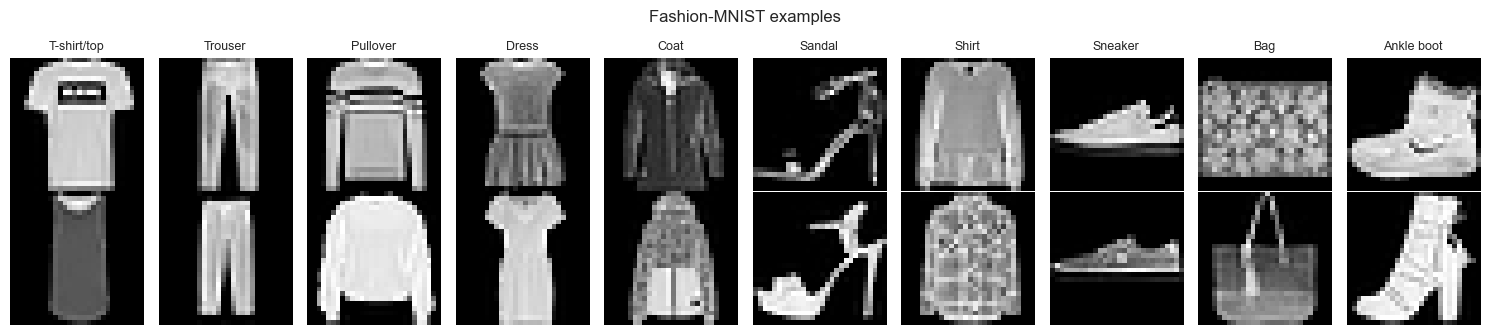

In [2]:
def load_images(name="MNIST"):
    """Download a torchvision dataset and return tensors (N,1,28,28) in [0,1] already on the device."""
    cls = getattr(torchvision.datasets, name)
    tr, te = cls("data", train=True, download=True), cls("data", train=False, download=True)
    to_t = lambda ds: ds.data.float().div(255.).unsqueeze(1).to(device)
    return to_t(tr), tr.targets.clone(), to_t(te), te.targets.clone(), tr.classes

def batches(X, bs, shuffle=True):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), bs):
        yield X[idx[i:i + bs]]

Xtr, ytr, Xte, yte, classes = load_images("FashionMNIST")
print("Train:", tuple(Xtr.shape), "Test:", tuple(Xte.shape))
print("Classes:", classes)
print("Images per class (train):", np.bincount(ytr.numpy()))

fig, axes = plt.subplots(2, 10, figsize=(15, 3.4))
for c in range(10):
    idx = (ytr == c).nonzero()[:2, 0]
    for r in range(2):
        axes[r, c].imshow(Xtr[idx[r], 0].cpu(), cmap="gray"); axes[r, c].axis("off")
    axes[0, c].set_title(classes[c], fontsize=9)
plt.suptitle("Fashion-MNIST examples"); plt.tight_layout(); plt.show()

## Task 2: Convolutional VAE design

```
ENCODER  q(z|x)                                   DECODER  p(x|z)
1×28×28                                           z (16)
 │ Conv 4×4, stride 2, 32 ch + ReLU  → 32×14×14     │ Linear → 256 → 64·7·7 + ReLU
 │ Conv 4×4, stride 2, 64 ch + ReLU  → 64×7×7       │ reshape 64×7×7
 │ Flatten → Linear 3136→256 + ReLU                 │ ConvTranspose 4×4, s2 → 32×14×14 + ReLU
 ├─ Linear 256→16  = μ                              │ ConvTranspose 4×4, s2 → 1×28×28
 └─ Linear 256→16  = log σ²                         │ Sigmoid  → x̂ in [0,1]
          │
   z = μ + σ ⊙ ε ,  ε ~ N(0, I)      (latent space, 16-D)
```
Convolutions use the 2-D structure of images, so the model needs far fewer parameters than an MLP and gives sharper reconstructions.

In [3]:
LATENT = 16

class ConvVAE(nn.Module):
    def __init__(self, latent_dim=LATENT):
        super().__init__()
        self.latent_dim = latent_dim
        # ---------------- Encoder ----------------
        self.enc = nn.Sequential(
            nn.Conv2d(1, 32, 4, 2, 1), nn.ReLU(),            # 32 x 14 x 14
            nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(),           # 64 x 7 x 7
            nn.Flatten(), nn.Linear(64 * 7 * 7, 256), nn.ReLU())
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        # ---------------- Decoder ----------------
        self.dec_fc = nn.Sequential(nn.Linear(latent_dim, 256), nn.ReLU(),
                                    nn.Linear(256, 64 * 7 * 7), nn.ReLU())
        self.dec = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),  # 32 x 14 x 14
            nn.ConvTranspose2d(32, 1, 4, 2, 1), nn.Sigmoid())  # 1 x 28 x 28

    def encode(self, x):
        h = self.enc(x); return self.fc_mu(h), self.fc_logvar(h)
    def reparameterize(self, mu, logvar):
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
    def decode(self, z):
        return self.dec(self.dec_fc(z).view(-1, 64, 7, 7))
    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decode(self.reparameterize(mu, logvar)), mu, logvar

model = ConvVAE().to(device)
print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

ConvVAE(
  (enc): Sequential(
    (0): Conv2d(1, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Flatten(start_dim=1, end_dim=-1)
    (5): Linear(in_features=3136, out_features=256, bias=True)
    (6): ReLU()
  )
  (fc_mu): Linear(in_features=256, out_features=16, bias=True)
  (fc_logvar): Linear(in_features=256, out_features=16, bias=True)
  (dec_fc): Sequential(
    (0): Linear(in_features=16, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=3136, bias=True)
    (3): ReLU()
  )
  (dec): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(32, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): Sigmoid()
  )
)
Trainable parameters: 1,688,289


## Task 3: Training

Loss per image = **BCE reconstruction** (summed over 784 pixels) + **KL divergence** to $\mathcal{N}(0,I)$, i.e. the negative ELBO. Optimiser: Adam, lr = 1e-3, batch size 128, **5 epochs**.

In [4]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    """Returns (total, reconstruction, KL), all SUMMED over the batch.
       recon = BCE(x_hat, x)                      ~  -E_q[log p(x|z)]
       KL    = -1/2 * sum(1 + log s^2 - mu^2 - s^2)  =  KL(q(z|x) || N(0, I))"""
    recon = F.binary_cross_entropy(x_hat.reshape(len(x), -1), x.reshape(len(x), -1), reduction="sum")
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon + beta * kl, recon, kl

def train_vae(model, Xtr, Xte, epochs=5, beta=1.0, lr=1e-3, bs=128, verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {k: [] for k in ["train_total", "train_recon", "train_kl", "test_total", "test_recon", "test_kl"]}
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); s = np.zeros(3)
        for xb in batches(Xtr, bs):
            x_hat, mu, logvar = model(xb)
            loss, rec, kl = vae_loss(x_hat, xb, mu, logvar, beta)
            opt.zero_grad(); loss.backward(); opt.step()
            s += [loss.item(), rec.item(), kl.item()]
        s /= len(Xtr)                                   # per-image averages
        te = evaluate(model, Xte, beta)
        for k, v in zip(hist, list(s) + list(te)): hist[k].append(v)
        if verbose:
            print(f"epoch {ep}/{epochs} | train total={s[0]:.2f} recon={s[1]:.2f} KL={s[2]:.2f} "
                  f"| test total={te[0]:.2f} recon={te[1]:.2f} KL={te[2]:.2f} ({time.time()-t0:.1f}s)")
    return hist

@torch.no_grad()
def evaluate(model, X, beta=1.0, bs=1000):
    model.eval(); s = np.zeros(3)
    for xb in batches(X, bs, shuffle=False):
        x_hat, mu, logvar = model(xb)
        s += [t.item() for t in vae_loss(x_hat, xb, mu, logvar, beta)]
    return s / len(X)

@torch.no_grad()
def encode_mu(model, X, bs=1000):
    model.eval()
    return torch.cat([model.encode(xb)[0] for xb in batches(X, bs, shuffle=False)]).cpu().numpy()

def show_grid(imgs, nrow, title=None, ax=None, size=1.0):
    imgs = imgs.detach().cpu().reshape(-1, 1, 28, 28)
    grid = torchvision.utils.make_grid(imgs, nrow=nrow, padding=2, pad_value=1).permute(1, 2, 0).numpy()
    if ax is None:
        plt.figure(figsize=(nrow * size, (len(imgs) // nrow) * size)); ax = plt.gca()
    ax.imshow(grid, cmap="gray"); ax.axis("off")
    if title: ax.set_title(title)

EPOCHS = 5
set_seed(42)
history = train_vae(model, Xtr, Xte, epochs=EPOCHS)

epoch 1/5 | train total=277.72 recon=265.56 KL=12.16 | test total=254.14 recon=241.39 KL=12.75 (8.2s)


epoch 2/5 | train total=248.46 recon=235.42 KL=13.04 | test total=247.18 recon=234.00 KL=13.18 (5.0s)


epoch 3/5 | train total=244.15 recon=231.00 KL=13.14 | test total=244.59 recon=231.33 KL=13.25 (5.0s)


epoch 4/5 | train total=242.09 recon=228.71 KL=13.38 | test total=243.39 recon=229.48 KL=13.91 (5.1s)


epoch 5/5 | train total=240.73 recon=227.19 KL=13.54 | test total=242.86 recon=229.27 KL=13.58 (4.9s)


,train_total,train_recon,train_kl,test_total,test_recon,test_kl
epoch,,,,,,
1,277.72,265.56,12.16,254.14,241.39,12.75
2,248.46,235.42,13.04,247.18,234.00,13.18
3,244.15,231.00,13.14,244.59,231.33,13.25
4,242.09,228.71,13.38,243.39,229.48,13.91
5,240.73,227.19,13.54,242.86,229.27,13.58


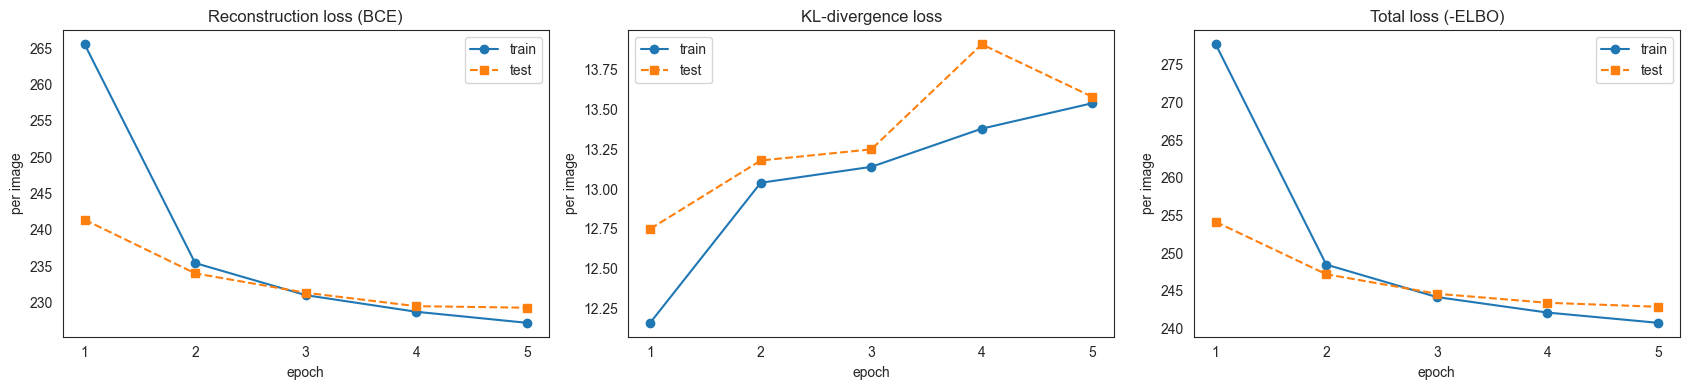

In [5]:
h = pd.DataFrame(history, index=pd.Index(range(1, EPOCHS + 1), name="epoch")).round(2)
display(h)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, k, t in zip(axes, ["recon", "kl", "total"], ["Reconstruction loss (BCE)", "KL-divergence loss", "Total loss (-ELBO)"]):
    ax.plot(h.index, h[f"train_{k}"], "o-", label="train"); ax.plot(h.index, h[f"test_{k}"], "s--", label="test")
    ax.set_title(t); ax.set_xlabel("epoch"); ax.set_ylabel("per image"); ax.legend(); ax.set_xticks(h.index)
plt.tight_layout(); plt.show()

**Reading the curves:** the reconstruction loss falls quickly, because the decoder learns the clothing shapes. The KL term usually **rises** at first and then levels off. That is expected: the encoder starts with distributions close to the prior (KL ≈ 0) and gradually puts information into $z$, paying KL for it. The total loss (−ELBO) decreases steadily. Train and test curves stay close, so there is **no overfitting**.

## Task 4: Original vs reconstructed images

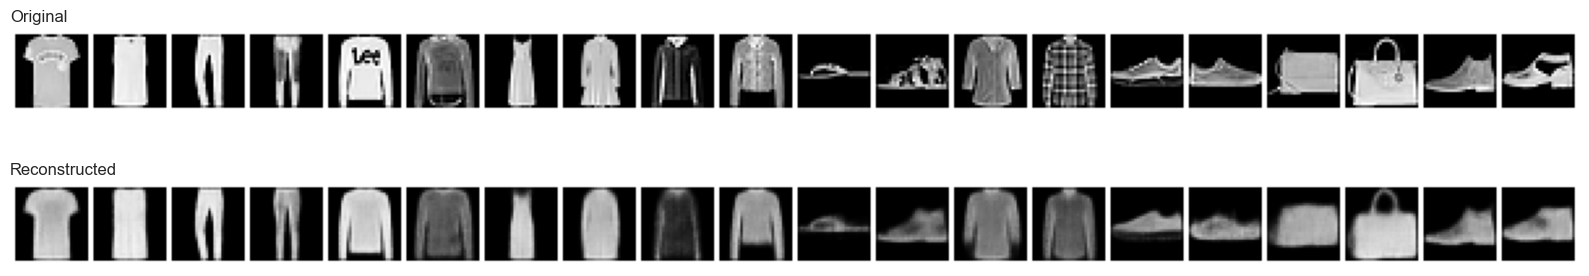

,Trouser,Sneaker,Coat,Dress,T-shirt/top,Ankle boot,Pullover,Shirt,Bag,Sandal
Reconstruction MSE,0.0084,0.0123,0.0133,0.0141,0.0143,0.0145,0.0146,0.0147,0.0215,0.023


In [6]:
model.eval()
idx = torch.cat([(yte == c).nonzero()[:2, 0] for c in range(10)])
x = Xte[idx]
with torch.no_grad():
    rec = model.decode(model.encode(x)[0])     # use the mean mu for a deterministic reconstruction
fig, axes = plt.subplots(2, 1, figsize=(16, 3.6))
show_grid(x, nrow=20, ax=axes[0]); axes[0].set_title("Original", loc="left")
show_grid(rec, nrow=20, ax=axes[1]); axes[1].set_title("Reconstructed", loc="left")
plt.tight_layout(); plt.show()

with torch.no_grad():
    mse_c = [F.mse_loss(model.decode(model.encode(Xte[yte == c])[0]), Xte[yte == c]).item() for c in range(10)]
pd.Series(mse_c, index=classes, name="Reconstruction MSE").sort_values().round(4).to_frame().T

Reconstructions keep the **overall shape, silhouette and brightness** of each item: trousers, bags and shoes are clearly recognisable. Fine details such as logos, prints and textures are **blurred**. This is the well-known blurriness of VAEs, caused by the pixel-wise likelihood and the averaging over the latent posterior. The per-class error table confirms it. **Trousers (MSE 0.008) and sneakers (0.012)**, which are simple, solid silhouettes, are reconstructed best. **Sandals (0.023) and bags (0.022)** are the worst: sandals consist of thin straps with gaps, and bags vary a lot in shape, handles and prints. These fine, high-frequency details are exactly what a 16-D Gaussian bottleneck averages away.

## Task 5: Visualising the learned latent space
The latent space is 16-D, so we project the encoder means $\mu(x)$ of 3,000 test images to 2-D with **PCA** (linear) and **t-SNE** (non-linear), and colour them by their *true* class.

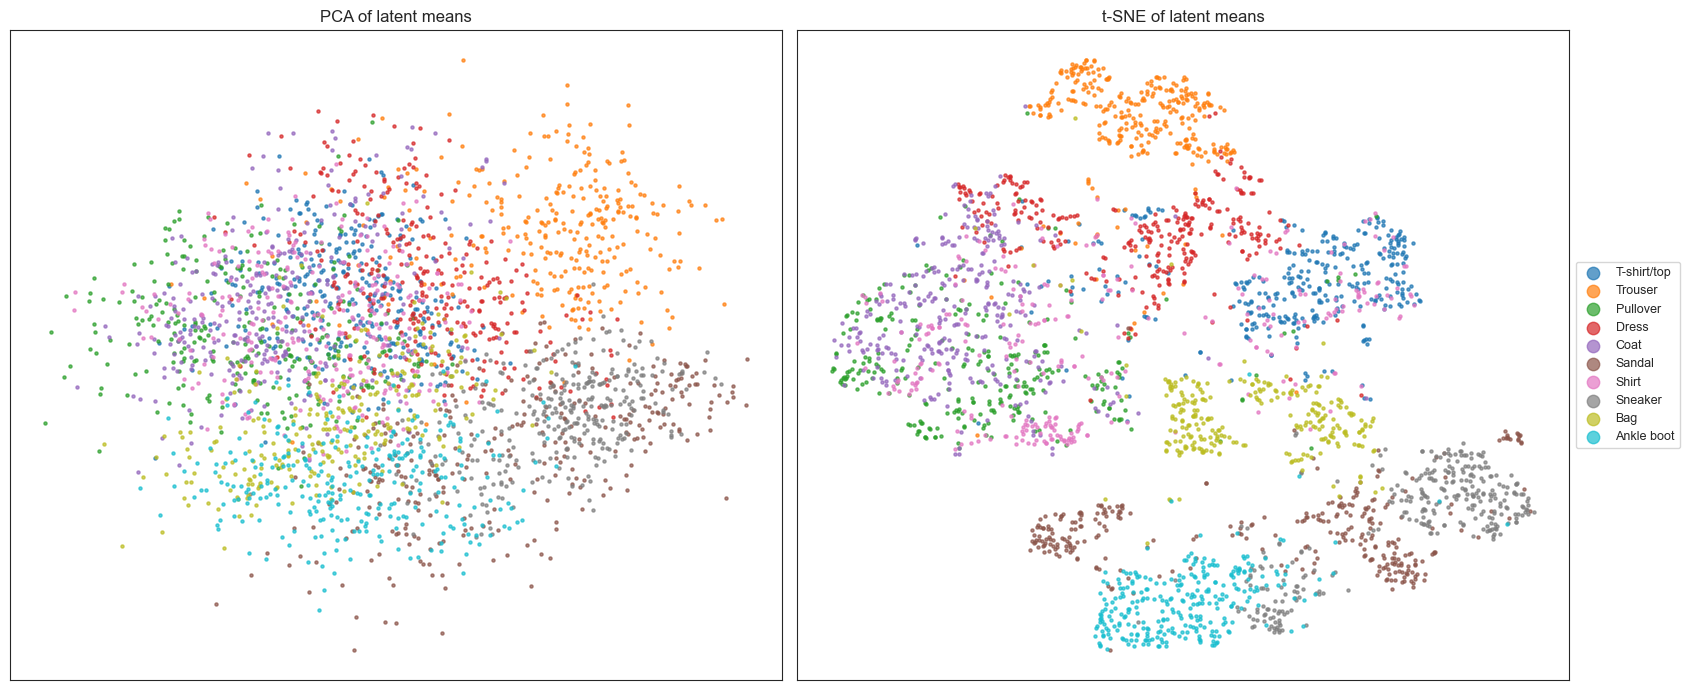

Mean of latent means per dim : [-0.03  0.03 -0.01  0.   -0.03  0.04  0.   -0.04 -0.04  0.01  0.02  0.01
  0.02 -0.02  0.02 -0.05]
Std  of latent means per dim : [0.95 0.04 0.08 0.06 0.81 0.21 0.95 0.97 1.13 1.1  0.07 0.08 0.96 0.08
 0.96 0.07]


In [7]:
sel = torch.randperm(len(Xte))[:3000]
Z = encode_mu(model, Xte[sel]); lab = yte[sel].numpy()
Z_pca = PCA(2).fit_transform(Z)
Z_tsne = TSNE(2, perplexity=30, random_state=42, init="pca").fit_transform(Z)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, P, t in zip(axes, [Z_pca, Z_tsne], ["PCA of latent means", "t-SNE of latent means"]):
    for c in range(10):
        ax.scatter(P[lab == c, 0], P[lab == c, 1], s=5, label=classes[c], alpha=0.7)
    ax.set_title(t); ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(markerscale=4, fontsize=9, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout(); plt.show()

# How close is the aggregate posterior to N(0, I)?
Zall = encode_mu(model, Xte)
print("Mean of latent means per dim :", Zall.mean(0).round(2))
print("Std  of latent means per dim :", Zall.std(0).round(2))

**Interpretation of the latent space**
* Although **no labels were used in training**, items of the same class form **clear clusters**. The VAE discovered the categories on its own, purely from appearance.
* The clusters are arranged by **visual similarity**:
  * **Footwear** (sandal, sneaker, ankle boot) forms its own region, far from clothing.
  * **Trousers** and **bags** are well-separated, compact clusters.
  * **Upper-body garments** (T-shirt, pullover, coat, shirt, dress) overlap strongly, because these items share silhouettes. This is exactly where humans also find Fashion-MNIST hard.
* The KL regulariser keeps the latent means **centred around 0** (all per-dimension means are within ±0.05), so the space is continuous and has no large "holes". This is what makes sampling possible in Task 6.
* The printed standard deviations show that only **about 8 of the 16 dimensions are really used** (std ≈ 0.8–1.1). The others have std < 0.1 and have collapsed to the prior. The VAE automatically "switches off" dimensions it does not need, because every used dimension costs KL.

### Smooth latent space: interpolation between two items

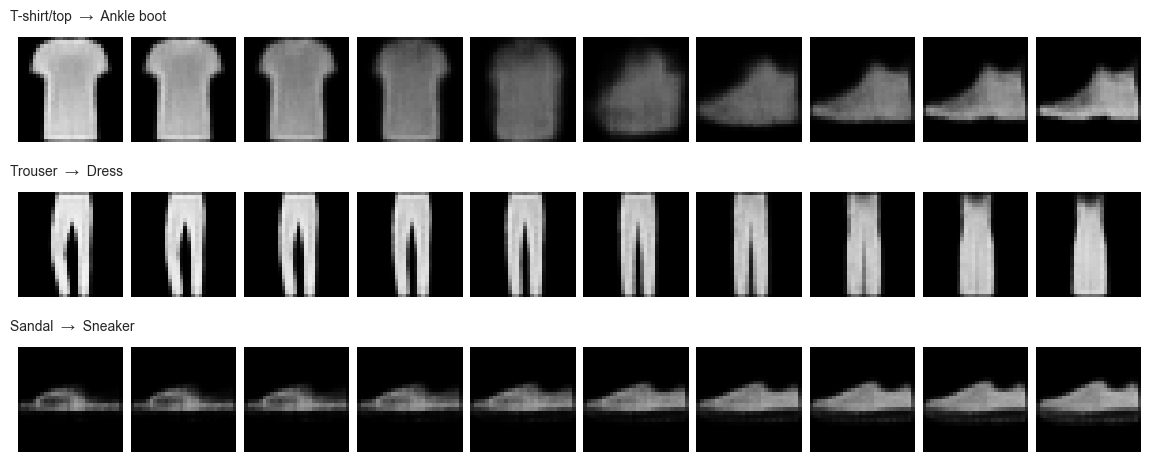

In [8]:
pairs = [(0, 9), (1, 3), (5, 7)]            # T-shirt->Ankle boot, Trouser->Dress, Sandal->Sneaker
fig, axes = plt.subplots(len(pairs), 1, figsize=(14, 1.6 * len(pairs)))
for ax, (a, b) in zip(axes, pairs):
    xa, xb = Xte[(yte == a).nonzero()[0, 0]], Xte[(yte == b).nonzero()[0, 0]]
    with torch.no_grad():
        za, zb = model.encode(xa[None])[0], model.encode(xb[None])[0]
        zs = torch.cat([za + t * (zb - za) for t in torch.linspace(0, 1, 10, device=device)])
        show_grid(model.decode(zs), nrow=10, ax=ax)
    ax.set_title(f"{classes[a]}  →  {classes[b]}", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## Task 6: Generating new synthetic samples and evaluating their quality
We sample $z \sim \mathcal{N}(0, I)$ and decode it.

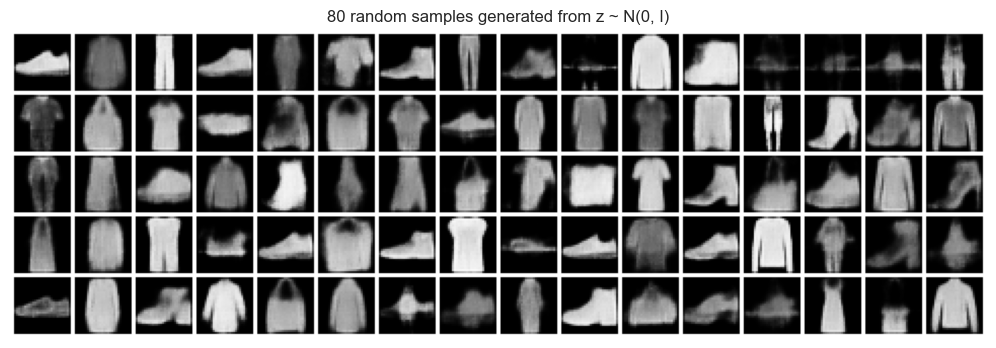

In [9]:
set_seed(7)
with torch.no_grad():
    gen = model.decode(torch.randn(1000, LATENT, device=device))
show_grid(gen[:80], nrow=16, title="80 random samples generated from z ~ N(0, I)", size=0.8)

### Quantitative evaluation of generated images
"Quality" has no single ground truth, so we use four simple, interpretable checks:
1. **Recognisability:** a classifier trained on real Fashion-MNIST predicts the class of each generated image. High confidence means the image looks like a real category.
2. **Diversity:** the predicted classes of the 1,000 samples should cover all 10 categories, not just a few (no *mode collapse*).
3. **Sharpness:** the mean gradient magnitude of the image (edge strength). Lower means blurrier.
4. **Novelty:** the distance to the nearest training image. It should not be ≈0, otherwise the model is just copying.

Classifier accuracy on REAL test images: 0.839


,Classifier confidence,Sharpness (edge strength),Distance to nearest train image
Real test images,0.860,0.079,3.843
VAE reconstructions,0.830,0.049,2.813
VAE generated samples,0.739,0.044,3.554


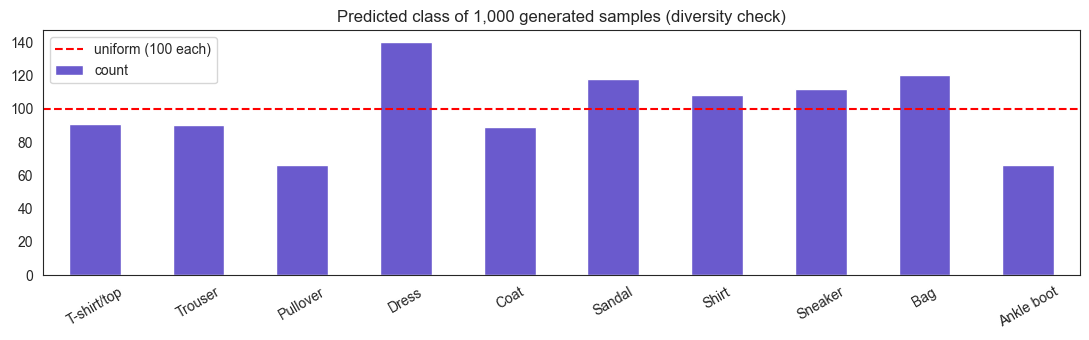

In [10]:
# 1) classifier trained on real images (simple multinomial logistic regression on pixels)
n_cls = 20000
clf = LogisticRegression(max_iter=300, C=0.5)
clf.fit(Xtr[:n_cls].view(n_cls, -1).cpu().numpy(), ytr[:n_cls].numpy())
real_acc = clf.score(Xte.view(len(Xte), -1).cpu().numpy(), yte.numpy())
print(f"Classifier accuracy on REAL test images: {real_acc:.3f}")

def confidence(imgs):
    p = clf.predict_proba(imgs.view(len(imgs), -1).cpu().numpy())
    return p.max(1), p.argmax(1)

with torch.no_grad():
    recon = model.decode(model.encode(Xte[:1000])[0])
conf_real, _ = confidence(Xte[:1000]); conf_rec, _ = confidence(recon); conf_gen, cls_gen = confidence(gen)

# 3) sharpness = mean absolute image gradient
def sharpness(imgs):
    dx = (imgs[..., :, 1:] - imgs[..., :, :-1]).abs().mean()
    dy = (imgs[..., 1:, :] - imgs[..., :-1, :]).abs().mean()
    return ((dx + dy) / 2).item()

# 4) novelty = distance to nearest training image
def nn_dist(imgs, ref):
    d = torch.cdist(imgs.view(len(imgs), -1), ref.view(len(ref), -1))
    return d.min(1).values.mean().item()
ref = Xtr[:20000]

quality = pd.DataFrame({
    "Classifier confidence": [conf_real.mean(), conf_rec.mean(), conf_gen.mean()],
    "Sharpness (edge strength)": [sharpness(Xte[:1000]), sharpness(recon), sharpness(gen)],
    "Distance to nearest train image": [nn_dist(Xte[:1000], ref), nn_dist(recon, ref), nn_dist(gen, ref)],
}, index=["Real test images", "VAE reconstructions", "VAE generated samples"]).round(3)
display(quality)

# 2) diversity
dist = pd.Series(cls_gen).map(dict(enumerate(classes))).value_counts().reindex(classes).fillna(0)
plt.figure(figsize=(11, 3.5)); dist.plot.bar(color="slateblue")
plt.axhline(100, color="red", ls="--", label="uniform (100 each)"); plt.legend()
plt.title("Predicted class of 1,000 generated samples (diversity check)"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

**Evaluation of the generated samples**
* **Recognisable:** most generated items are clearly identifiable as trousers, shoes, bags, dresses or tops. The real-data classifier (83.9 % accurate on real test images) is on average **74 % confident** on generated samples, compared with 86 % on real images and 83 % on reconstructions. Samples are fairly realistic, but less clear-cut than real photos.
* **Diverse:** the 1,000 samples cover **all 10 categories** (between about 65 and 140 per class), so there is **no mode collapse**. *Dress* is over-represented and *pullover / ankle boot* are under-represented. Blurry, average-looking garments are easily read as a dress.
* **Novel:** the mean distance to the nearest training image (3.55) is close to that of real *test* images (3.84), so the VAE produces **new** items rather than copies of training images. Reconstructions (2.81) are closer to the training data, because they are averaged versions of real images.
* **Blurry:** the edge strength of generated samples (0.044) is only **about 55 %** of that of real images (0.079). Fine textures and patterns are missing, and some samples are "average" shapes that mix two categories (e.g. between a pullover and a coat). This is the typical **limitation of VAEs** compared with GANs or diffusion models.

**Summary:** the convolutional VAE learned, without labels, a smooth 16-D latent space that organises clothing by visual similarity. It reconstructs the overall shape well and generates plausible, diverse, but blurry new fashion items after only 5 epochs.